# Pengenalan Vokal Bahasa Indonesia

In [26]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'config.yaml').is_file():
    raise FileNotFoundError('Buka notebook ini dari folder root proyek.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from vowel_recognition.config import load_config
from vowel_recognition.data_loader import build_manifest, validate_dataset, dataset_summary
from vowel_recognition.preprocessing import preprocess_audio
from vowel_recognition.features import extract_features
from vowel_recognition.templates import build_templates, save_templates
from vowel_recognition.gaussian_model import build_models
from vowel_recognition.recognition import predict_batch
from vowel_recognition.evaluation import add_averages, build_speaker_table, build_vowel_table, evaluate
from vowel_recognition.visualization import save_confusion, save_accuracy_comparison


## 1. Muat konfigurasi dan validasi dataset

In [27]:
config = load_config(PROJECT_ROOT / 'config.yaml')
manifest, validation_errors = validate_dataset(config)
print(dataset_summary(manifest, validation_errors))
display(manifest)
if validation_errors:
    print('\nError dataset:')
    print(*validation_errors, sep='\n')
else:
    print('Valid dataset')

Expected recordings: 50 | speakers: 5 | vowels: 5 | validation issues: 0


,file_path,speaker_id,true_vowel,split
0,D:\Downloads\vowel-recognition\data\S01\a\trai...,S01,a,train
1,D:\Downloads\vowel-recognition\data\S01\a\test...,S01,a,test
2,D:\Downloads\vowel-recognition\data\S01\i\trai...,S01,i,train
3,D:\Downloads\vowel-recognition\data\S01\i\test...,S01,i,test
4,D:\Downloads\vowel-recognition\data\S01\u\trai...,S01,u,train
5,D:\Downloads\vowel-recognition\data\S01\u\test...,S01,u,test
6,D:\Downloads\vowel-recognition\data\S01\e\trai...,S01,e,train
7,D:\Downloads\vowel-recognition\data\S01\e\test...,S01,e,test
8,D:\Downloads\vowel-recognition\data\S01\o\trai...,S01,o,train
9,D:\Downloads\vowel-recognition\data\S01\o\test...,S01,o,test


Valid dataset


## 2. Pemuatan audio, prapemrosesan, dan MFCC


File: D:\Downloads\vowel-recognition\data\S01\a\train.wav
Sample rate: 16000 Hz
MFCC: (124, 39)


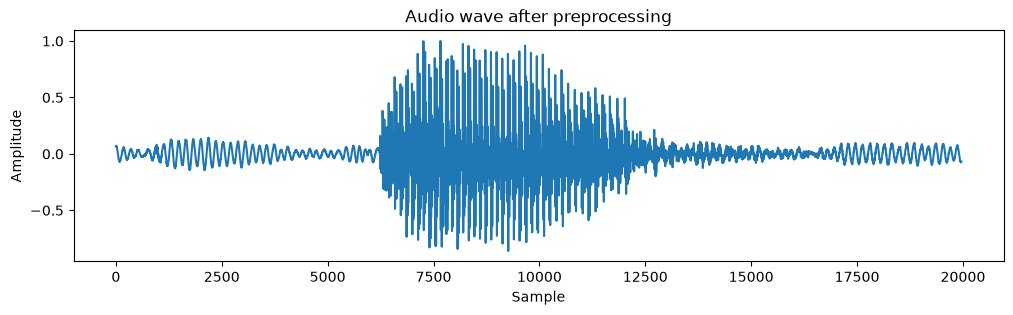

In [28]:
if not validation_errors:
    example = manifest.iloc[0]
    audio, sample_rate = preprocess_audio(example.file_path, config)
    mfcc_features = extract_features(audio, sample_rate, config)
    print(f"File: {example.file_path}\nSample rate: {sample_rate} Hz\nMFCC: {mfcc_features.shape}")
    plt.figure(figsize=(12, 3))
    plt.plot(audio)
    plt.title('Audio wave after preprocessing')
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')
    plt.show()
else:
    print('Skip.')

## 3. Jalankan eksperimen DTW dan Gaussian

In [29]:
metrics = None
artifacts = None

if not validation_errors:
    np.random.seed(config.get('random_seed', 42))
    results_dir = Path(config['results']['dir'])
    tables_dir = results_dir / 'tables'
    figures_dir = results_dir / 'figures'
    cache_dir = results_dir / 'feature_cache'
    tables_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    def load_features(file_path: str) -> np.ndarray:
        relative_path = Path(file_path).relative_to(Path(config['data']['directory']))
        cache_path = (cache_dir / relative_path).with_suffix('.npy')
        if config.get('cache_features', True) and cache_path.is_file():
            return np.load(cache_path)
        audio, rate = preprocess_audio(file_path, config)
        features = extract_features(audio, rate, config)
        if config.get('cache_features', True):
            cache_path.parent.mkdir(parents=True, exist_ok=True)
            np.save(cache_path, features)
        return features

    train_manifest = manifest[manifest.split == 'train'].copy()
    training_features = {row.file_path: load_features(row.file_path) for row in train_manifest.itertuples()}
    features_by_vowel = {
        vowel: [training_features[row.file_path] for row in train_manifest[train_manifest.true_vowel == vowel].itertuples()]
        for vowel in config['data']['vowels']
    }
    artifacts = {
        'dtw': build_templates(features_by_vowel, config['dtw']['normalize']),
        'gaussian': build_models(features_by_vowel, config['gaussian']['regularization']),
    }
    save_templates(artifacts['dtw'], results_dir / 'artifacts')

    scenarios = {'closed_recording': train_manifest, 'closed_speakers': manifest[manifest.split == 'test']}
    open_speakers = config['data'].get('open_test_speakers', [])
    if open_speakers:
        scenarios['open_speakers'] = build_manifest(config, open_speakers, ('test',))

    metrics = {}
    for system in ('dtw', 'gaussian'):
        metrics[system] = {}
        for scenario, scenario_manifest in scenarios.items():
            predictions = predict_batch(scenario_manifest, system, artifacts[system], config)
            pd.DataFrame(predictions).to_csv(tables_dir / f'predictions_{system}_{scenario}.csv', index=False)
            metric = evaluate(predictions, config['data']['vowels'])
            metrics[system][scenario] = metric
            save_confusion(metric, f'{system} - {scenario}', figures_dir / f'confusion_{system}_{scenario}.png')
        if 'open_speakers' not in metrics[system]:
            metrics[system]['open_speakers'] = evaluate([], config['data']['vowels'])

    comparison_rows = []
    for system, scenario_metrics in metrics.items():
        available_scores = [metric['accuracy'] for metric in scenario_metrics.values() if metric['available']]
        comparison_rows.append({
            'System': system,
            'Closed Recording (%)': scenario_metrics['closed_recording']['accuracy'],
            'Closed Speakers (%)': scenario_metrics['closed_speakers']['accuracy'],
            'Open Speakers (%)': scenario_metrics['open_speakers']['accuracy'],
            'Average (%)': float(np.mean(available_scores)) if available_scores else None,
        })
    pd.DataFrame(comparison_rows).to_csv(tables_dir / 'comparison.csv', index=False)
    vowel_table = build_vowel_table(metrics, config['data']['vowels'])
    vowel_table.to_csv(tables_dir / 'vowel_accuracy.csv', index=False)
    closed_speaker_table = build_speaker_table(metrics, scenarios=['closed_recording', 'closed_speakers'])
    closed_speaker_table.to_csv(tables_dir / 'speaker_accuracy_closed.csv', index=False)
    open_speaker_table = build_speaker_table(metrics, scenarios=['open_speakers'])
    open_speaker_table.to_csv(tables_dir / 'speaker_accuracy_open.csv', index=False)
    (results_dir / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
    (results_dir / 'experiment_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    if config.get('generate_plots', True):
        save_accuracy_comparison(metrics, figures_dir / 'accuracy_comparison.png')
    print('Done. Output saved in:', results_dir)

else:
    print('Skip.')

Done. Output saved in: D:\Downloads\vowel-recognition\results


## 4. Tampilkan dan simpan hasil

In [30]:
results_dir = Path(config['results']['dir'])
comparison_path = results_dir / 'tables' / 'comparison.csv'
metrics_path = results_dir / 'metrics.json'
if comparison_path.is_file():
    display(pd.read_csv(comparison_path))
if metrics_path.is_file():
    saved_metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
    print(json.dumps(saved_metrics, indent=2))

table_reports = [
    ('Akurasi per vokal (%)', 'vowel_accuracy.csv', 'Vowel'),
    ('Akurasi per speaker - eksperimen closed (%)', 'speaker_accuracy_closed.csv', 'Speaker'),
    ('Akurasi per speaker - eksperimen open (%)', 'speaker_accuracy_open.csv', 'Speaker'),
]
for title, filename, index_name in table_reports:
    table_path = results_dir / 'tables' / filename
    if not table_path.is_file():
        continue
    table = pd.read_csv(table_path)
    print(f'\n{title}')
    if table.empty:
        print('(no data)')
        continue
    display(add_averages(table, index_name).round(2))

print('\nTabel saved:')
for path in sorted((results_dir / 'tables').glob('*.csv')):
    print('-', path.relative_to(PROJECT_ROOT))
print('\nImage saved:')
for path in sorted((results_dir / 'figures').glob('*.png')):
    print('-', path.relative_to(PROJECT_ROOT))


,System,Closed Recording (%),Closed Speakers (%),Open Speakers (%),Average (%)
0,dtw,100.0,84.0,85.00,89.666667
1,gaussian,100.0,84.0,71.25,85.083333


{
  "dtw": {
    "closed_recording": {
      "available": true,
      "accuracy": 100.0,
      "evaluated": 25,
      "failed": 0,
      "skipped": 0,
      "correct": 25,
      "incorrect": 0,
      "per_vowel": {
        "a": 100.0,
        "e": 100.0,
        "i": 100.0,
        "o": 100.0,
        "u": 100.0
      },
      "per_speaker": {
        "S01": 100.0,
        "S02": 100.0,
        "S03": 100.0,
        "S04": 100.0,
        "S05": 100.0
      },
      "confusion_matrix": [
        [
          5,
          0,
          0,
          0,
          0
        ],
        [
          0,
          5,
          0,
          0,
          0
        ],
        [
          0,
          0,
          5,
          0,
          0
        ],
        [
          0,
          0,
          0,
          5,
          0
        ],
        [
          0,
          0,
          0,
          0,
          5
        ]
      ],
      "labels": [
        "a",
        "i",
        "u",
        "e",
     

,Vowel,DTW Closed Recording (%),DTW Closed Speakers (%),DTW Open Speakers (%),Gaussian Closed Recording (%),Gaussian Closed Speakers (%),Gaussian Open Speakers (%),Average (%)
0,a,100.0,100.0,93.75,100.0,100.0,93.75,97.92
1,i,100.0,100.0,100.00,100.0,80.0,87.50,94.58
2,u,100.0,60.0,93.75,100.0,60.0,37.50,75.21
3,e,100.0,100.0,81.25,100.0,100.0,68.75,91.67
4,o,100.0,60.0,56.25,100.0,80.0,68.75,77.50
5,Average,100.0,84.0,85.00,100.0,84.0,71.25,87.38



Akurasi per speaker - eksperimen closed (%)


,Speaker,DTW Closed Recording (%),DTW Closed Speakers (%),Gaussian Closed Recording (%),Gaussian Closed Speakers (%),Average (%)
0,S01,100.0,60.0,100.0,60.0,80.0
1,S02,100.0,60.0,100.0,60.0,80.0
2,S03,100.0,100.0,100.0,100.0,100.0
3,S04,100.0,100.0,100.0,100.0,100.0
4,S05,100.0,100.0,100.0,100.0,100.0
5,Average,100.0,84.0,100.0,84.0,92.0



Akurasi per speaker - eksperimen open (%)


,Speaker,DTW Open Speakers (%),Gaussian Open Speakers (%),Average (%)
0,S06,80.0,60.00,70.00
1,S07,60.0,40.00,50.00
2,S08,80.0,80.00,80.00
3,S09,80.0,60.00,70.00
4,S10,80.0,80.00,80.00
5,S11,100.0,80.00,90.00
6,S12,100.0,80.00,90.00
7,S13,100.0,60.00,80.00
8,S14,100.0,80.00,90.00
9,S15,100.0,80.00,90.00



Tabel saved:
- results\tables\comparison.csv
- results\tables\predictions_dtw_closed_recording.csv
- results\tables\predictions_dtw_closed_speakers.csv
- results\tables\predictions_dtw_open_speakers.csv
- results\tables\predictions_gaussian_closed_recording.csv
- results\tables\predictions_gaussian_closed_speakers.csv
- results\tables\predictions_gaussian_open_speakers.csv
- results\tables\speaker_accuracy_closed.csv
- results\tables\speaker_accuracy_open.csv
- results\tables\vowel_accuracy.csv

Image saved:
- results\figures\accuracy_comparison.png
- results\figures\confusion_dtw_closed_recording.png
- results\figures\confusion_dtw_closed_speakers.png
- results\figures\confusion_dtw_open_speakers.png
- results\figures\confusion_gaussian_closed_recording.png
- results\figures\confusion_gaussian_closed_speakers.png
- results\figures\confusion_gaussian_open_speakers.png
